In [1]:
import sys
sys.path.append(r'/Users/kostastsampourakis/Desktop/code/Python/projects/gaussfiltax')

import time

from jax import numpy as jnp
from jax import random as jr
from jax import lax, vmap, pmap, jacfwd, jacrev, debug, device_put, jit
from tensorflow_probability.substrates.jax.distributions import MultivariateNormalFullCovariance as MVN
from typing import List, Optional, NamedTuple, Union
from jaxtyping import Array, Float, Int

# import tensorflow as tf
# tf.test.gpu_device_name()

import gaussfiltax.utils as utils
import gaussfiltax.inference as gf
from gaussfiltax.inference import ParamsUKF, _ukf_predict_nonadditive, PosteriorGaussianSumFiltered, _process_input, _get_params, swap_axes_on_values
from gaussfiltax.models import ParamsNLSSM, NonlinearSSM, ParamsBPF


import scienceplots
import matplotlib.pyplot as plt
import matplotlib_inline

plt.style.use(['science', 'ieee'])
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

In [2]:
# Parameters
state_dim = 10
state_noise_dim = 10
emission_dim = 10
emission_noise_dim = 10
seq_length = 140
mu0 = 0.0 * jnp.zeros(state_dim)
q0 = jnp.zeros(state_noise_dim)
r0 = 0.0001 * jnp.ones(emission_noise_dim)
Sigma0 = 1.0 * jnp.eye(state_dim)
Q = 10.0 * jnp.eye(state_noise_dim)
R = 0.1 * jnp.eye(emission_noise_dim)

# Model functions
Phi = 0.8 * jnp.eye(state_dim)
fmsv = lambda x, q, u: Phi @ x + q

sigma = 4.0
beta = 0.5
H0 = jnp.eye(emission_dim, state_dim)
glmsv = lambda x, r, u: u * beta * jnp.multiply(jnp.exp(x / sigma), r) + (1-u) * (H0 @ x + r)
def lmsvlp(x,y,u):
    M = u * beta * jnp.diag(jnp.exp(x / sigma)) + (1-u) * jnp.eye(emission_dim)
    return MVN(loc = glmsv(x, r0, u), covariance_matrix = M @ R @ M.T).log_prob(y)

# Inputs
# inputs = jnp.array([0]*int(seq_length/2) + [1]*int(seq_length/2)) # off - on
# inputs = vmap(lambda x: jnp.sin(0.1 * x)**2)(jnp.arange(seq_length)) # sine_sq
inputs = vmap(lambda x: (1 - jnp.sin(0.2 * x))/2)(jnp.arange(seq_length)) # sine
# inputs = jr.uniform(jr.PRNGKey(0), (seq_length,))
# inputs = jnp.zeros(seq_length) # off
# inputs = jnp.ones(seq_length) # on
# plt.plot(inputs)
# plt.show()

f = fmsv
g = glmsv
glp = lmsvlp

In [3]:
# initialization
model = NonlinearSSM(state_dim, state_noise_dim, emission_dim, emission_noise_dim)
params = ParamsNLSSM(
    initial_mean=mu0,
    initial_covariance=Sigma0,
    dynamics_function=f,
    dynamics_noise_bias= q0,
    dynamics_noise_covariance=Q,
    emission_function=g,
    emission_noise_bias= r0,
    emission_noise_covariance=R,
)

In [4]:
verbose = False
Nsim = 100
# rho1, rho2 = jnp.meshgrid(0.99 * jnp.arange(1, 2), 0.1 * jnp.arange(1, 10))
# rho_values = jnp.array([0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]) #  
rho1_values = jnp.array([0.9])
rho2_values = jnp.array([10**(-i) for i in range(-1, 15)]) # for reviewer 4, evaluation of gamma (adaptive)
rho1, rho2 = jnp.meshgrid(rho1_values, rho2_values)
opt_arg_pairs = jnp.array([rho1.ravel(), rho2.ravel()]).T
# opt_arg_pairs = jnp.array([jnp.array([0.05, 0.05])])
gsf_mse = jnp.zeros(Nsim)
ugsf_mse = jnp.zeros(Nsim)
agsf_mse = jnp.zeros((Nsim, len(opt_arg_pairs)))
uagsf_mse = jnp.zeros((Nsim, len(opt_arg_pairs)))
bpf_mse = jnp.zeros(Nsim)

gsf_norm = jnp.zeros((Nsim, seq_length))
ugsf_norm = jnp.zeros((Nsim, seq_length))
agsf_norm = jnp.zeros((Nsim, seq_length, len(opt_arg_pairs)))
uagsf_norm = jnp.zeros((Nsim, seq_length, len(opt_arg_pairs)))
bpf_norm = jnp.zeros((Nsim, seq_length))

gsf_time = jnp.zeros(Nsim)
ugsf_time = jnp.zeros(Nsim)
agsf_time = jnp.zeros(Nsim)
uagsf_time = jnp.zeros(Nsim)
bpf_time = jnp.zeros(Nsim)
gspf_time = jnp.zeros(Nsim)
next_key = jr.PRNGKey(10)


for i in range(Nsim):
    print('sim {}/{}'.format(i+1, Nsim))
    # Generate Data
    key0, key, next_key = jr.split(next_key, 3)
    print('key0: ', key0)
    print('key: ', key)
    states, emissions = model.sample(params, key0, seq_length, inputs = inputs)

    M = 1
    # # GSF   
    # tin = time.time()
    # posterior_filtered_gsf = gf.gaussian_sum_filter(params, emissions, M, 1, key, inputs)
    # point_estimate_gsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_gsf.means, posterior_filtered_gsf.weights), axis=0)
    # tout = time.time()
    # t_gsf= tout - tin
    # print('       Time taken for GSF: ', tout - tin)

    # # U-GSF
    # tin = time.time()
    # uparams = ParamsUKF(1,0,0)
    # posterior_filtered_ugsf = gf.unscented_gaussian_sum_filter(params, uparams, emissions, M, 1, key, inputs)
    # point_estimate_ugsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_ugsf.means, posterior_filtered_ugsf.weights), axis=0)
    # tout = time.time()
    # t_ugsf= tout - tin
    # print('       Time taken for UGSF: ', tout - tin)

    num_components = [10, 5, 5]

    # AGSF
    tin = time.time()
    posterior_filtered_agsf, aux_outputs = vmap(gf.augmented_gaussian_sum_filter, in_axes=(None, None, None, None, None, 0, None))(params, emissions, num_components, key, 1, opt_arg_pairs, inputs)    
    point_estimates_agsf = vmap(lambda posterior_filtered: jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered.means, posterior_filtered.weights), axis=0))(posterior_filtered_agsf)
    tout = time.time()
    t_agsf= tout - tin
    print('       Time taken for AGSF: ', tout - tin)

    # # U-AGSF
    # tin = time.time()
    # posterior_filtered_uagsf, aux_outputs = vmap(gf.unscented_agsf, in_axes=(None, None, None, None, None, 0, None))(params, uparams, emissions, num_components, key, opt_arg_pairs, inputs)
    # point_estimates_uagsf = vmap(lambda posterior_filtered: jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered.means, posterior_filtered.weights), axis=0))(posterior_filtered_uagsf)
    # tout = time.time()
    # t_uagsf = tout - tin
    # print('       Time taken for UAGSF: ', tout - tin)

    # # BPF
    # tin = time.time()
    # num_particles = 10

    # params_bpf = ParamsBPF(
    #     initial_mean=mu0,
    #     initial_covariance=Sigma0,
    #     dynamics_function=f,
    #     dynamics_noise_bias=q0,
    #     dynamics_noise_covariance=Q,
    #     emission_function=g,
    #     emission_noise_bias=r0,
    #     emission_noise_covariance=R,
    #     emission_distribution_log_prob = glp
    # )

    # posterior_bpf = gf.bootstrap_particle_filter(params_bpf, emissions, num_particles, key, inputs, 1.0)
    # point_estimate_bpf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_bpf["particles"], posterior_bpf["weights"]), axis=0)
    # tout = time.time()
    # t_bpf = tout - tin
    # print('       Time taken for BPF: ', tout - tin)


    # Computation of errors
    # gsf_norm = gsf_norm.at[i].set(jnp.linalg.norm(point_estimate_gsf - states, axis = 1)**2)
    agsf_norm = agsf_norm.at[i].set(vmap(lambda point_estimate: jnp.linalg.norm(point_estimate[:] - states[:], axis = 1)**2)(point_estimates_agsf).T)
    # bpf_norm = bpf_norm.at[i].set(jnp.linalg.norm(point_estimate_bpf - states, axis = 1)**2)

    gsf_mse = gsf_mse.at[i].set(jnp.mean(gsf_norm[i]))
    agsf_mse = agsf_mse.at[i].set(jnp.mean(agsf_norm[i], axis = 0))
    bpf_mse = bpf_mse.at[i].set(jnp.mean(bpf_norm[i]))

    # gsf_time = gsf_time.at[i].set(t_gsf)
    agsf_time = agsf_time.at[i].set(t_agsf)
    # bpf_time = bpf_time.at[i].set(t_bpf)


sim 1/100
key0:  [1325352869 2119862813]
key:  [ 407539183 3392237303]
       Time taken for AGSF:  4.00623893737793
sim 2/100
key0:  [3766254757 3870263153]
key:  [4287846969 1299354295]
       Time taken for AGSF:  3.5240938663482666
sim 3/100
key0:  [3845949649 1539386963]
key:  [3213239570 3063266243]
       Time taken for AGSF:  3.5398099422454834
sim 4/100
key0:  [4200415619 1930591809]
key:  [ 347551405 3685003213]
       Time taken for AGSF:  3.4261770248413086
sim 5/100
key0:  [2828274776  122520982]
key:  [1590444941  648097440]
       Time taken for AGSF:  3.4756290912628174
sim 6/100
key0:  [3343020820  716683468]
key:  [1563849553 1771877459]
       Time taken for AGSF:  3.5041937828063965
sim 7/100
key0:  [3209406664  380628721]
key:  [1413435023 2111504146]
       Time taken for AGSF:  3.508417844772339
sim 8/100
key0:  [4244954398  511748954]
key:  [3397515289 1240158027]
       Time taken for AGSF:  3.471524715423584
sim 9/100
key0:  [2025336454 1353743969]
key:  [4172

In [5]:
import pandas as pd

# Remove NaNs and compute success percentage
ind_gsf = jnp.unique(jnp.argwhere(jnp.isnan(gsf_mse)))
gsf_mse = jnp.delete(gsf_mse, ind_gsf, axis = 0)
gsf_success_pct = int(100 - 100*len(ind_gsf) / Nsim)

ind_ugsf = jnp.unique(jnp.argwhere(jnp.isnan(ugsf_mse)))
# ugsf_rmse = jnp.delete(ugsf_rmse, ind_ugsf, axis = 0)
ugsf_success_pct = int(100 - 100* len(ind_ugsf) / Nsim)

ind_bpf = jnp.unique(jnp.argwhere(jnp.isnan(bpf_mse)))
bpf_rmse = jnp.delete(bpf_mse, ind_bpf, axis = 0)
bpf_success_pct = int(100 - 100*len(ind_bpf) / Nsim)


keys = jr.split(jr.PRNGKey(0), 5)
B = 100
gsf_boot = utils.bootstrap(keys[0], gsf_mse, B)
ugsf_boot = utils.bootstrap(keys[1], ugsf_mse, B)
bpf_boot = utils.bootstrap(keys[2], bpf_rmse, B)
pct_agsf, armse_agsf, std_agf = utils.vec_clean_and_rmse(agsf_mse, keys[3], B, Nsim)
# pct_uagsf, armse_uagsf, std_uagf = utils.vec_clean_and_rmse(uagsf_rmse, keys[4], B, Nsim)

# gsf_armse = jnp.mean(gsf_boot)
# ugsf_armse = jnp.mean(ugsf_boot)
# bpf_armse = jnp.mean(bpf_boot)

gsf_atime = jnp.mean(gsf_time)
ugsf_atime = jnp.mean(ugsf_time)
agsf_atime = jnp.mean(agsf_time)
uagsf_atime = jnp.mean(uagsf_time)
bpf_atime = jnp.mean(bpf_time)

# gsf_tab_out = '{:2.3f}±{:2.2f}({}%)'.format(gsf_armse, jnp.std(gsf_rmse), gsf_success_pct)
# # ugsf_tab_out = '{:2.3f}±{:2.2f}({}%)'.format(ugsf_armse, jnp.std(ugsf_rmse), ugsf_success_pct)
# bpf_tab_out = '{:2.3f}±{:2.2f}({}%)'.format(bpf_armse, jnp.std(bpf_boot), bpf_success_pct)
# agsf_tab_out = ['{:2.3f}±{:2.2f}({}%)'.format(armse_agsf[i], std_agf[i], pct_agsf[i]) for i in range(len(armse_agsf))]
# uagsf_tab_out = ['{:2.3f}±{:2.2f}({}%)'.format(armse_uagsf[i], std_uagf[i], pct_uagsf[i]) for i in range(len(armse_uagsf))]

In [6]:
print(opt_arg_pairs)
print(jnp.array(armse_agsf))
print(pct_agsf)
print(opt_arg_pairs[jnp.argmin(jnp.array(armse_agsf))])
print(jnp.min(jnp.array(armse_agsf)))

[[9.e-01 1.e+01]
 [9.e-01 1.e+00]
 [9.e-01 1.e-01]
 [9.e-01 1.e-02]
 [9.e-01 1.e-03]
 [9.e-01 1.e-04]
 [9.e-01 1.e-05]
 [9.e-01 1.e-06]
 [9.e-01 1.e-07]
 [9.e-01 1.e-08]
 [9.e-01 1.e-09]
 [9.e-01 1.e-10]
 [9.e-01 1.e-11]
 [9.e-01 1.e-12]
 [9.e-01 1.e-13]
 [9.e-01 1.e-14]]
[ 58.714867  59.274017  67.638596  56.358612  63.444225  50.405468
  39.50945   40.2647    33.972744  36.76797   59.301395 111.47961
 164.7687   195.4548   221.68213  241.53355 ]
[99, 99, 100, 99, 100, 99, 99, 100, 100, 100, 100, 100, 100, 100, 100, 100]
[9.e-01 1.e-07]
33.972744


In [7]:
# import seaborn as sns
# import matplotlib.pyplot as plt
# import numpy as np
# from matplotlib.colors import LinearSegmentedColormap, Normalize
# from matplotlib.patches import Circle


# # Sample data for demonstration purposes
# # Replace this with your actual data

# # Define a custom colormap
# colors = ["#08306b", "#4292c6", "#9ecae1", "#c6dbef", "#f7fbff"]
# n_bins = 100  # Discretize the interpolation into bins
# cmap_name = "custom_blue"

# # Create the colormap
# custom_cmap = LinearSegmentedColormap.from_list(cmap_name, colors, N=n_bins)
# colormap = sns.color_palette("YlGnBu", as_cmap=True)


# # Normalize the data to emphasize the middle range
# class MidpointNormalize(Normalize):
#     def __init__(self, vmin=None, vmax=None, midpoint=None, clip=False):
#         self.midpoint = midpoint
#         Normalize.__init__(self, vmin, vmax, clip)

#     def __call__(self, value, clip=None):
#         # I'm ignoring masked values and all kinds of edge cases to make a simple example...
#         result, is_scalar = self.process_value(value)
#         self.autoscale_None(result)
#         vmin, vmax, midpoint = self.vmin, self.vmax, self.midpoint

#         result = np.ma.masked_array(np.interp(result, [vmin, midpoint, vmax], [0, 0.5, 1.0]), np.isnan(result))
#         if is_scalar:
#             result = result[0]
#         return result

# # Creating the heatmap
# data = jnp.array(armse_agsf).reshape(len(rho1_values), len(rho2_values))
# vmin = jnp.min(data) # jnp.min(jnp.array([jnp.min(data), jnp.min(gsf_mse), jnp.min(bpf_mse)]))
# vmax = jnp.max(data) # jnp.max(jnp.array([jnp.max(data), jnp.max(gsf_mse), jnp.max(bpf_mse)]))
# kappa = 0.5 # Adjust the value of kappa as needed
# norm = MidpointNormalize(vmin=vmin, vmax=vmax, midpoint= vmin + kappa * (vmax - vmin))  # Adjust the midpoint as needed
# ax = sns.heatmap(jnp.flip(data, 0), cmap='YlGnBu', linewidth=.5, norm=norm)

# # Setting the labels for x and y ticks
# ax.set_xticklabels(rho2_values)
# ax.set_yticklabels(jnp.flip(rho1_values, 0))
# ax.set_xlabel(r'$\rho_1$')
# ax.set_ylabel(r'$\rho_2$')
# # plt.locator_params(axis='y', nbins=11)
# # plt.locator_params(axis='x', nbins=11)
# ax.xaxis.set_minor_locator(plt.NullLocator())
# ax.yaxis.set_minor_locator(plt.NullLocator())
# ax.tick_params(top=False, right=False)
# ax.collections[0].colorbar.set_label('AMSE')
# ax.collections[0].colorbar.set_ticks([8.0, 10.0, 12.0, 14.0, 16.0, 18.0]) 
# # ax.collections[0].colorbar.set_ticklabels([5.0, 12.5, 20.0, 25.0, 27.5])

# circle_gsf_color = colormap(jnp.mean(gsf_mse))
# circle_bpf_color = colormap(jnp.mean(bpf_mse))
# circle_gsf = Circle((1.0, 0.0), 0.02, transform=ax.transAxes, color=circle_gsf_color, zorder=10)
# circle_bpf = Circle((0.0, 1.0), 0.02, transform=ax.transAxes, color=circle_bpf_color, zorder=10)

# # ax.add_patch(circle_gsf)
# # ax.add_patch(circle_bpf)

# # Display the plot
# plt.show()
# plt.savefig(r'/Users/kostastsampourakis/Desktop/code/Python/projects/gaussfiltax/output/heatmap.eps', format='eps')


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


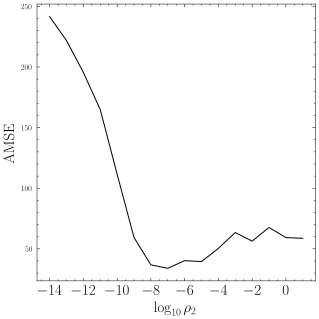

In [8]:
plt.figure(figsize=(5, 5))
plt.plot(jnp.log10(rho2_values), armse_agsf)
plt.xticks(fontsize=15)
plt.xlabel(r'$\log_{10} \rho_2$', fontsize=15)
plt.ylabel('AMSE', fontsize=15)
# plt.tick_params(top=False, right=False)
plt.legend(prop = { "size": 11 })
plt.show()

In [9]:
import pandas as pd

# Remove NaNs and compute success percentage
ind_gsf = jnp.unique(jnp.argwhere(jnp.isnan(gsf_mse)))
gsf_mse = jnp.delete(gsf_mse, ind_gsf, axis = 0)
gsf_norm = jnp.delete(gsf_norm, ind_gsf, axis = 0)
gsf_success_pct = int(100 - 100*len(ind_gsf) / Nsim)

ind_ugsf = jnp.unique(jnp.argwhere(jnp.isnan(ugsf_mse)))
ugsf_mse = jnp.delete(ugsf_mse, ind_ugsf, axis = 0)
ugsf_norm = jnp.delete(ugsf_norm, ind_ugsf, axis = 0)
ugsf_success_pct = int(100 - 100* len(ind_ugsf) / Nsim)

ind_agsf = jnp.unique(jnp.argwhere(jnp.isnan(agsf_mse)))
agsf_mse = jnp.delete(agsf_mse, ind_agsf, axis = 0)
agsf_norm = jnp.delete(agsf_norm, ind_agsf, axis = 0)
agsf_success_pct = int(100 - 100*len(ind_agsf) / Nsim)

ind_uagsf = jnp.unique(jnp.argwhere(jnp.isnan(uagsf_mse)))
uagsf_mse = jnp.delete(uagsf_mse, ind_uagsf, axis = 0)
uagsf_norm = jnp.delete(uagsf_norm, ind_uagsf, axis = 0)
uagsf_success_pct = int(100 - 100*len(ind_uagsf) / Nsim)

ind_bpf = jnp.unique(jnp.argwhere(jnp.isnan(bpf_mse)))
bpf_mse = jnp.delete(bpf_mse, ind_bpf, axis = 0)
bpf_norm = jnp.delete(bpf_norm, ind_bpf, axis = 0)
bpf_success_pct = int(100 - 100*len(ind_bpf) / Nsim)

# ind_apf = jnp.unique(jnp.argwhere(jnp.isnan(apf_mse)))
# apf_mse = jnp.delete(apf_mse, ind_apf, axis = 0)
# apf_norm = jnp.delete(apf_norm, ind_apf, axis = 0)
# apf_success_pct = int(100 - 100*len(ind_apf) / Nsim)

# ind_gspf = jnp.unique(jnp.argwhere(jnp.isnan(gspf_mse)))
# gspf_mse = jnp.delete(gspf_mse, ind_gspf, axis = 0)
# gspf_norm = jnp.delete(gspf_norm, ind_gspf, axis = 0)
# gspf_success_pct = int(100 - 100*len(ind_gspf) / Nsim)


keys = jr.split(jr.PRNGKey(0), 7)
B = 100
gsf_boot = utils.bootstrap(keys[0], gsf_mse, B)
ugsf_boot = utils.bootstrap(keys[1], ugsf_mse, B)
agsf_boot = utils.bootstrap(keys[2], agsf_mse, B)
uagsf_boot = utils.bootstrap(keys[3], uagsf_mse, B)
bpf_boot = utils.bootstrap(keys[4], bpf_mse, B)
# apf_boot = utils.bootstrap(keys[5], apf_mse, B)
# gspf_boot = utils.bootstrap(keys[6], gspf_mse, B)

gsf_amse = jnp.mean(gsf_boot)
ugsf_amse = jnp.mean(ugsf_boot)
agsf_amse = jnp.mean(agsf_boot)
uagsf_amse = jnp.mean(uagsf_boot)
bpf_amse = jnp.mean(bpf_boot)
# apf_amse = jnp.mean(apf_boot)
# gspf_amse = jnp.mean(gspf_boot)

gsf_atime = jnp.mean(gsf_time)
ugsf_atime = jnp.mean(ugsf_time)
agsf_atime = jnp.mean(agsf_time)
uagsf_atime = jnp.mean(uagsf_time)
bpf_atime = jnp.mean(bpf_time)
# apf_atime = jnp.mean(apf_time)
# gspf_atime = jnp.mean(gspf_time)

gsf_tab_out = '${:2.3f}\pm{:2.3f}({}\%)$'.format(gsf_amse, jnp.std(gsf_boot), gsf_success_pct)
ugsf_tab_out = '${:2.3f}\pm{:2.3f}({}\%)$'.format(ugsf_amse, jnp.std(ugsf_boot), ugsf_success_pct)
agsf_tab_out = '${:2.3f}\pm{:2.3f}({}\%)$'.format(agsf_amse, jnp.std(agsf_boot), agsf_success_pct)
uagsf_tab_out = '${:2.3f}\pm{:2.3f}({}\%)$'.format(uagsf_amse, jnp.std(uagsf_boot), uagsf_success_pct)
bpf_tab_out = '${:2.3f}\pm{:2.3f}({}\%)$'.format(bpf_amse, jnp.std(bpf_boot), bpf_success_pct)
# apf_tab_out = '${:2.3f}\pm{:2.3f}({}\%)$'.format(apf_amse, jnp.std(apf_boot), apf_success_pct)
# gspf_tab_out = '${:2.3f}\pm{:2.3f}({}\%)$'.format(gspf_amse, jnp.std(gspf_boot), gspf_success_pct)

gsf_tab_out1 = '${:2.2f}\pm{:2.2f}$'.format(gsf_atime, jnp.std(gsf_time))
ugsf_tab_out1 = '${:2.2f}\pm{:2.2f}$'.format(ugsf_atime, jnp.std(ugsf_time))
agsf_tab_out1 = '${:2.2f}\pm{:2.2f}$'.format(agsf_atime, jnp.std(agsf_time))
uagsf_tab_out1 = '${:2.2f}\pm{:2.2f}$'.format(uagsf_atime, jnp.std(uagsf_time))
bpf_tab_out1 = '${:2.2f}\pm{:2.2f}$'.format(bpf_atime, jnp.std(bpf_time))
# apf_tab_out1 = '${:2.2f}\pm{:2.2f}$'.format(apf_atime, jnp.std(apf_time))
# gspf_tab_out1 = '${:2.2f}\pm{:2.2f}$'.format(gspf_atime, jnp.std(gspf_time))

df = pd.DataFrame(columns = [' ','RMSE','time(s)'])
# df[' '] = ['GSF', 'AGSF', 'AGSF Optimal', 'BPF']
# df['RMSE'] = [gsf_tab_out, agsf_tab_out, agsf_opt_tab_out, bpf_tab_out]
# df['time(s)'] = [gsf_tab_out1, agsf_tab_out1, agsf_opt_tab_out1, bpf_tab_out1]
df[' '] = ['GSF','UGSF', 'AGSF', 'UAGSF', 'BPF']
df['RMSE'] = [gsf_tab_out, ugsf_tab_out, agsf_tab_out, uagsf_tab_out, bpf_tab_out]
df['time(s)'] = [gsf_tab_out1, ugsf_tab_out1, agsf_tab_out1, uagsf_tab_out1, bpf_tab_out1]
print(df.to_latex(index=False))
df

\begin{tabular}{lll}
\toprule
  & RMSE & time(s) \\
\midrule
GSF & $0.000\pm0.000(100\%)$ & $0.00\pm0.00$ \\
UGSF & $0.000\pm0.000(100\%)$ & $0.00\pm0.00$ \\
AGSF & $90.106\pm2.670(93\%)$ & $3.47\pm0.08$ \\
UAGSF & $0.000\pm0.000(100\%)$ & $0.00\pm0.00$ \\
BPF & $0.000\pm0.000(100\%)$ & $0.00\pm0.00$ \\
\bottomrule
\end{tabular}



,,RMSE,time(s)
0,GSF,$0.000\pm0.000(100\%)$,$0.00\pm0.00$
1,UGSF,$0.000\pm0.000(100\%)$,$0.00\pm0.00$
2,AGSF,$90.106\pm2.670(93\%)$,$3.47\pm0.08$
3,UAGSF,$0.000\pm0.000(100\%)$,$0.00\pm0.00$
4,BPF,$0.000\pm0.000(100\%)$,$0.00\pm0.00$


In [10]:
aux_outputs['rho2s'].shape

(16, 140, 50)

rho2:  10.0


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


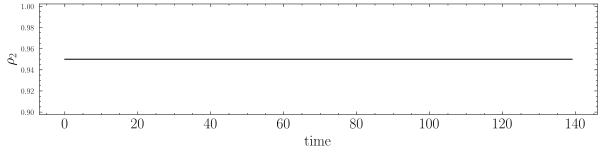

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


rho2:  1.0


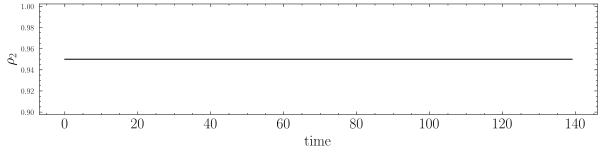

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


rho2:  0.1


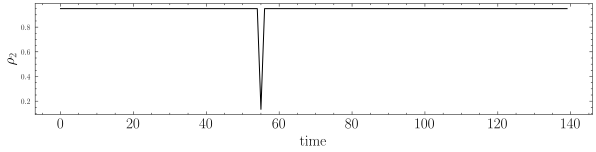

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


rho2:  0.01


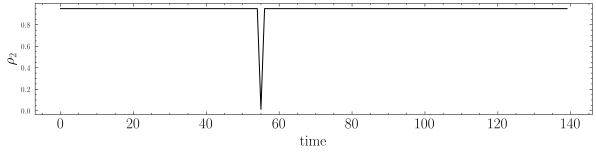

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


rho2:  0.001


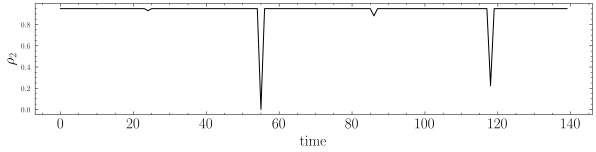

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


rho2:  1e-04


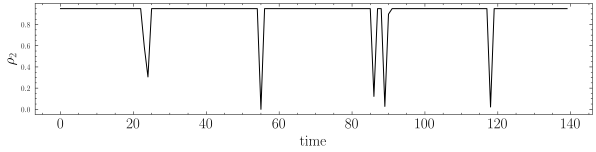

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


rho2:  1e-05


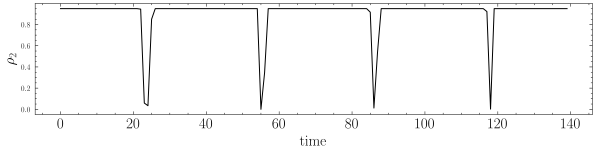

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


rho2:  1e-06


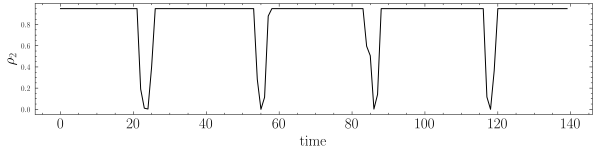

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


rho2:  1e-07


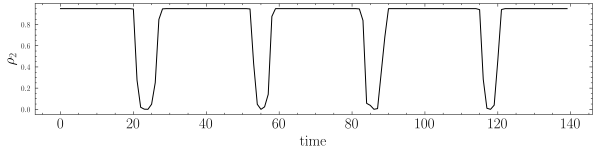

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


rho2:  1e-08


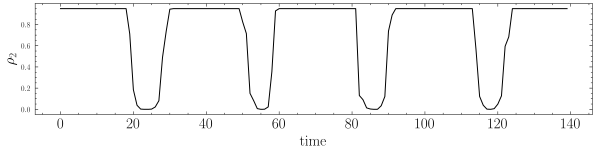

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


rho2:  1e-09


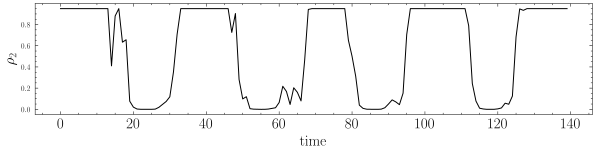

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


rho2:  1e-10


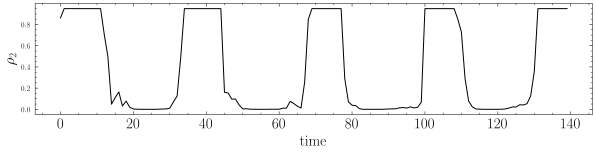

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


rho2:  1e-11


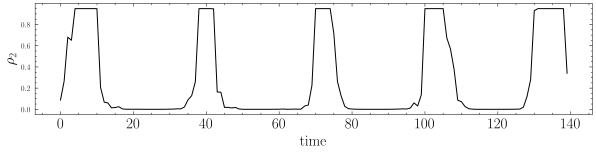

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


rho2:  1e-12


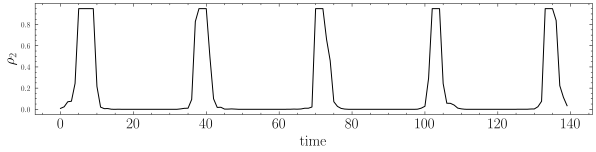

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


rho2:  1e-13


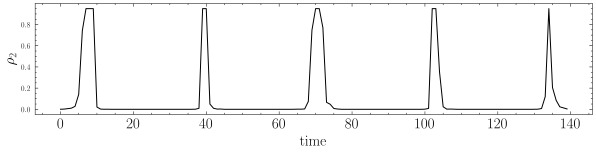

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


rho2:  1e-14


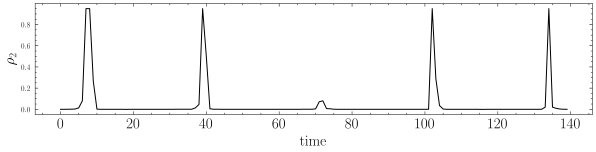

In [11]:
# plt.plot()
for i in range(len(rho2_values)):
    print('rho2: ', rho2_values[i])
    plt.figure(figsize=(10, 2))
    plt.plot(jnp.mean(aux_outputs['rho2s'][i], axis=1))
    plt.xticks(fontsize=15)
    plt.xlabel(r'time', fontsize=15)
    plt.ylabel(r'$\rho_2$', fontsize=15)
    plt.legend(prop = { "size": 11 })
    plt.show()